# 05 · Estadística descriptiva de la fertilidad (2016-2024) y validación de los datos

Produce las tablas de la sección *Estadística Descriptiva de Fertilidad en Argentina*, la figura
de no linealidad entre ingreso y fecundidad y las tablas de construcción de datos del Apéndice.

**Método de hijos propios.** Cada niño de edad 0 se atribuye a sus madres posibles en el hogar
(jefa o cónyuge para los hijos del jefe; hijas del jefe para los nietos), con una diferencia de
edad mínima de 14 años; si hay `k` candidatas, cada una recibe `1/k` del nacimiento. Las tasas
usan el ponderador ajustado del notebook 04 (factor único para la edad 0 y sus madres). La
precisión de cada comparación 2016-2024 se evalúa con un *bootstrap* de 1.000 réplicas que
remuestrea hogares completos (semilla fija).

**Tablas que produce** (`resultados/tablas/descriptivas/`):

| Archivo | Contenido en la tesis |
|---|---|
| `tabla1_asimetria_educativa.csv` | Asimetría educativa en la caída de la TGF |
| `tabla0_composicion_mujeres_edu3.csv` | Participación de cada nivel educativo (paréntesis de la tabla anterior) |
| `tabla2_espejismo_tempo.csv` | Descomposición de la edad media a la maternidad (MAC) |
| `tabla3_tempo_por_estrato.csv` | Variación de la MAC truncada por nivel educativo |
| `tabla4_contribucion_edad.csv` | Contribución de cada tramo de edad a la caída de la TGF |
| `tabla5_composicion_nacimientos_status.csv`, `tabla_educacion_vs_ingreso_*.csv`, `tabla_test_*.csv` | Ingreso vs. clima educativo (texto) |
| `tabla8_recomposicion_clima_serie.csv`, `tabla8b_recomposicion_clima_puntas.csv` | Recomposición de los nacimientos por clima educativo (texto y figura del notebook 08) |
| `tasa_fecundidad_status_2024.csv` | Datos de la figura de no linealidad |
| `validacion_nacional.csv` | TBN de la EPH vs. estadísticas vitales, total del país (Apéndice) |
| `validacion_jurisdicciones.csv` | TBN de la EPH vs. estadísticas vitales, por grupo de jurisdicciones (Apéndice) |
| `clima_educativo_cinco_categorias.csv` | Mujeres 15-49 por clima educativo del hogar (Apéndice) |

**Figura:** `resultados/figuras/barras_tradeoff_natalidad_2024.png`. Usa el decil de ingreso per
cápita familiar (IPCF) del corte 2024, con la maternidad reconstruida como en el modelo y la
imputación por mediana de los ingresos faltantes.

**Validación (Apéndice).** La tasa bruta de natalidad (TBN) de la EPH toma como nacimientos a
todos los niños de edad 0 (con el ponderador original y con el ajustado) y como población al
total expandido; se compara con la TBN de las estadísticas vitales de la DEIS. El intervalo de
confianza del grupo de jurisdicciones urbanas es un *bootstrap* de 1.000 réplicas por hogar.

**Entradas:** `resultados/intermedios/eph_corregida/` (notebook 04), `datos/eph/personas_tot.urb_3T_2024.txt`,
`datos/deis/`.

**Tiempo aproximado:** 3 minutos.

In [1]:
import os
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
DIR_IN = Path("resultados/intermedios/eph_corregida")
DIR_TAB = Path("resultados/tablas/descriptivas")
DIR_FIG = Path("resultados/figuras")
for d in (DIR_TAB, DIR_FIG):
    d.mkdir(parents=True, exist_ok=True)

ANIOS = list(range(2016, 2025))
Y0, Y1 = 2016, 2024
COL_NUM, COL_DEN = "w_bebe", "pondera"
COLS = ["codusu", "nro_hogar", "componente", "ano4", "provincia", "aglomerado", "ch03", "ch04", "ch06",
        "ch07", "ch12", "ch13", "ch14", "nivel_ed", "estado", "ipcf", "itf", "pondera", "pondera_orig",
        "pondih", "edad_eph", "factor_edad0"]
EDU3 = {7: "Bajo", 1: "Bajo", 2: "Bajo", 3: "Medio", 4: "Medio", 5: "Alto", 6: "Alto"}
TRAMOS = [(15, 19), (20, 24), (25, 29), (30, 34), (35, 39), (40, 44), (45, 49)]

## Carga y atribución de los nacimientos

In [2]:
def get_ed_years(df):
    nivel, finalizado, aprobado, educacion = df['ch12'], df['ch13'], df['ch14'], df['education']
    primaria, egb, secundaria, terciario, universidad, posgrado = 6, 9, 12, 14, 16, 18
    aprobado_valido = aprobado.notna() & ~aprobado.isin([98, 99])
    aprobado_safe = aprobado.fillna(0)
    fin1 = finalizado == 1
    val1 = pd.Series(0.0, index=df.index)
    val2 = np.select([fin1, aprobado_valido, educacion == 2],
                     [primaria, np.minimum(aprobado_safe, primaria - 0.5), primaria], default=primaria / 2)
    val3 = np.select([fin1, aprobado_valido, educacion == 2],
                     [egb, np.minimum(aprobado_safe, egb - 0.5), primaria], default=egb / 2)
    val4 = np.select([fin1, aprobado_valido, educacion == 4],
                     [secundaria, np.minimum(primaria + aprobado_safe, secundaria - 0.5), secundaria],
                     default=primaria + 3)
    val5 = np.select([fin1, aprobado_valido, educacion == 4],
                     [secundaria, np.minimum(egb + aprobado_safe, secundaria - 0.5), secundaria],
                     default=egb + 1.5)
    val6 = np.select([fin1, aprobado_valido, educacion == 6],
                     [terciario, np.minimum(secundaria + aprobado_safe, terciario - 0.5), terciario],
                     default=secundaria + 1)
    val7 = np.select([fin1, aprobado_valido, educacion == 6],
                     [universidad, np.minimum(secundaria + aprobado_safe, universidad - 0.5), universidad],
                     default=secundaria + 2.5)
    val8 = np.select([fin1, aprobado_valido],
                     [posgrado, np.minimum(universidad + aprobado_safe, posgrado - 0.5)], default=universidad + 1)
    val9 = np.select([educacion == i for i in range(1, 7)],
                     [primaria / 2, primaria, primaria + 3, secundaria, secundaria + 2, universidad], default=0.0)
    condiciones = [nivel == 1, nivel == 2, nivel == 3, nivel == 4, nivel == 5, nivel == 6, nivel == 7,
                   nivel == 8, nivel.isin([9, 99]) | nivel.isna()]
    return np.select(condiciones, [val1, val2, val3, val4, val5, val6, val7, val8, val9], default=0.0)


def tramo(edad):
    return pd.cut(edad, [t[0] for t in TRAMOS] + [50], labels=[f"{a}-{b}" for a, b in TRAMOS], right=False)


def deciles_ponderados(valor, peso, mascara):
    out = pd.Series(np.nan, index=valor.index)
    v, w = valor[mascara], peso[mascara]
    orden = v.sort_values(kind="mergesort").index
    acum = w.loc[orden].cumsum()
    out.loc[orden] = np.ceil(acum / acum.iloc[-1] * 10).clip(1, 10).values
    return out


def cargar(anio):
    df = pd.read_parquet(DIR_IN / f"personas_tot.urb_3T_{anio}_pondera_corregida.parquet", columns=COLS)
    df["year"] = anio
    df["edad"] = df["edad_eph"].astype(int)
    df["mujer"] = df["ch04"] == 2
    df["hogar"] = df["codusu"].astype(str) + "|" + df["nro_hogar"].astype(str)
    for c in ["ipcf", "itf"]:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    for c in ["pondera", "pondera_orig", "pondih", "ch12", "ch13", "ch14"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    for c in ["pondera", "pondera_orig", "pondih"]:
        df[c] = df[c].fillna(0.0)
    df["education"] = pd.to_numeric(df["nivel_ed"], errors="coerce").replace(7, 0)
    df["ed_years"] = get_ed_years(df)
    df = df.merge(df.loc[df["edad"] >= 18].groupby("hogar")["ed_years"].mean().rename("clima_anios"),
                  on="hogar", how="left")
    df["clima_edu"] = pd.cut(df["clima_anios"], [-np.inf, 11, 14, np.inf], right=False,
                             labels=["Clima bajo (<11 años)", "Clima medio (11-14)", "Clima alto (14 o más)"])
    df["edu3"] = df["nivel_ed"].map(EDU3)
    df["adultos"] = df.groupby("hogar")["edad"].transform(lambda s: (s >= 18).sum()).clip(lower=1)
    df["ing_adulto"] = df["itf"] / df["adultos"]
    df["decil_adulto"] = deciles_ponderados(df["ing_adulto"], df["pondih"],
                                            df["ing_adulto"].notna() & (df["pondih"] > 0))
    return df


def atribuir_hijos(df, edad_max=40):
    hijos = df.loc[(df["edad"] <= edad_max) & (df["ch03"].isin([3, 5])),
                   ["hogar", "ch03", "edad", "pondera", "pondera_orig"]].copy()
    hijos["hijo_id"] = hijos.index
    madres_jc = df.loc[df["mujer"] & df["edad"].between(15, 49) & df["ch03"].isin([1, 2]),
                       ["hogar", "edad"]].rename(columns={"edad": "m_edad"})
    madres_jc["madre_id"] = madres_jc.index
    madres_hi = df.loc[df["mujer"] & df["edad"].between(15, 49) & (df["ch03"] == 3),
                       ["hogar", "edad"]].rename(columns={"edad": "m_edad"})
    madres_hi["madre_id"] = madres_hi.index
    par = pd.concat([hijos[hijos["ch03"] == 3].merge(madres_jc, on="hogar", how="inner"),
                     hijos[hijos["ch03"] == 5].merge(madres_hi, on="hogar", how="inner")], ignore_index=True)
    par = par[(par["m_edad"] - par["edad"]) >= 14]
    par["n_cand"] = par.groupby("hijo_id")["madre_id"].transform("size")
    par["frac"] = 1.0 / par["n_cand"]
    par["w"] = par["pondera"] * par["frac"]
    par["w_orig"] = par["pondera_orig"] * par["frac"]
    return par


MUJ = []
for y in ANIOS:
    df = cargar(y)
    par = atribuir_hijos(df)
    m = df.loc[df["mujer"] & df["edad"].between(15, 49)].copy()
    bebes = par[par["edad"] == 0]
    m["w_bebe"] = m.index.map(bebes.groupby("madre_id")["w"].sum()).fillna(0.0)
    m["w_bebe_orig"] = m.index.map(bebes.groupby("madre_id")["w_orig"].sum()).fillna(0.0)
    m["n_bebe"] = m.index.map(bebes.groupby("madre_id")["frac"].sum()).fillna(0.0)
    m["edad_hijo_mayor"] = m.index.map(par.groupby("madre_id")["edad"].max())
    m["tramo"] = tramo(m["edad"])
    MUJ.append(m)
muj = pd.concat(MUJ, ignore_index=True)
muj = muj[muj["edad"].between(15, 49)].copy()
print(f"[panel] {len(muj):,} mujeres de 15 a 49 años, {Y0}-{Y1}")

[panel] 190,339 mujeres de 15 a 49 años, 2016-2024


## Estimadores y *bootstrap* por hogar

In [3]:
rng = np.random.default_rng(2024)


def tgf_de(d, emin=15, emax=49):
    d = d[d["edad"].between(emin, emax)]
    if d.empty:
        return np.nan
    g = d.groupby("edad", observed=True).apply(
        lambda x: pd.Series({"B": x[COL_NUM].sum(), "W": x[COL_DEN].sum()}), include_groups=False)
    return float(np.where(g["W"] > 0, g["B"] / g["W"], 0.0).sum())


def mac_de(d, emin=15):
    d = d[d["edad"] >= emin]
    return float(np.average(d["edad"], weights=d[COL_NUM])) if d[COL_NUM].sum() > 0 else np.nan


def _boot(d, estimador, n=1000):
    d = d.sort_values("hogar")
    codes, uniq = pd.factorize(d["hogar"], sort=False)
    nH = len(uniq)
    edad, num, den = d["edad"].to_numpy(float), d[COL_NUM].to_numpy(), d[COL_DEN].to_numpy()
    idx = (edad - 15).astype(int)
    out = np.empty(n)
    for r in range(n):
        m = rng.multinomial(nH, np.full(nH, 1.0 / nH))[codes]
        if estimador == "tgf":
            B = np.bincount(idx, weights=m * num, minlength=35)
            W = np.bincount(idx, weights=m * den, minlength=35)
            out[r] = np.sum(np.divide(B, W, out=np.zeros(35), where=W > 0))
        else:
            out[r] = np.sum(m * num * edad) / np.sum(m * num)
    return out


def contraste(d0, d1, estimador, n=1000, relativo=False):
    b0, b1 = _boot(d0, estimador, n), _boot(d1, estimador, n)
    a, b = rng.permutation(b0), rng.permutation(b1)
    dif = (b / a - 1) * 100 if relativo else b - a
    lo, hi = np.percentile(dif, [2.5, 97.5])
    p = 2 * min((dif <= 0).mean(), (dif >= 0).mean())
    return float(np.median(dif)), float(lo), float(hi), float(max(p, 1.0 / n))


def aporte_a_tgf(d, by):
    num = d.groupby(["year", by, "edad"], observed=True)[COL_NUM].sum().reset_index(name="B")
    den = d.groupby(["year", "edad"], observed=True)[COL_DEN].sum().reset_index(name="W")
    t = num.merge(den, on=["year", "edad"], how="left")
    t["aporte"] = t["B"] / t["W"]
    return t.groupby(["year", by], observed=True)["aporte"].sum().reset_index()


m0, m1 = muj[muj.year == Y0], muj[muj.year == Y1]
NIVELES = ["Bajo", "Medio", "Alto"]

## Tabla 1 · Asimetría educativa en la caída de la TGF

In [4]:
filas = []
for niv in NIVELES + ["Total"]:
    s0 = m0 if niv == "Total" else m0[m0.edu3 == niv]
    s1 = m1 if niv == "Total" else m1[m1.edu3 == niv]
    t0, t1 = tgf_de(s0), tgf_de(s1)
    p0, p1 = tgf_de(s0, emin=25), tgf_de(s1, emin=25)
    rel, lo, hi, pv = contraste(s0, s1, "tgf", relativo=True)
    filas.append(dict(nivel_educativo=niv, TGF_2016=t0, TGF_2024=t1, variacion_relativa=(t1 - t0) / t0,
                      variacion_absoluta=t1 - t0, var_rel_IC95_inf=lo / 100, var_rel_IC95_sup=hi / 100,
                      p_valor_bootstrap=pv, significativo_95=("sí" if pv < 0.05 else "no"),
                      TGF_parcial_25_49_2016=p0, TGF_parcial_25_49_2024=p1,
                      var_rel_parcial_25_49=(p1 - p0) / p0,
                      casos_madres_2016=int((s0["n_bebe"] > 0).sum()), casos_madres_2024=int((s1["n_bebe"] > 0).sum()),
                      mujeres_2016=s0[COL_DEN].sum(), mujeres_2024=s1[COL_DEN].sum()))
t1_df = pd.DataFrame(filas)
t1_df.to_csv(DIR_TAB / "tabla1_asimetria_educativa.csv", index=False)
t1_df[["nivel_educativo", "TGF_2016", "TGF_2024", "variacion_relativa", "p_valor_bootstrap",
       "casos_madres_2016", "casos_madres_2024"]].round(3)

,nivel_educativo,TGF_2016,TGF_2024,variacion_relativa,p_valor_bootstrap,casos_madres_2016,casos_madres_2024
0,Bajo,2.424,2.403,-0.009,0.888,197,56
1,Medio,1.970,1.454,-0.262,0.042,683,350
2,Alto,1.540,0.819,-0.468,0.001,326,186
3,Total,1.836,1.199,-0.347,0.001,1206,592


## Tablas 2 y 3 · Calendario (*tempo*): MAC original y truncada

In [5]:
primi = muj[(muj["n_bebe"] > 0) & (muj["edad_hijo_mayor"] == 0)]
p0, p1 = primi[primi.year == Y0], primi[primi.year == Y1]
filas = []
for nombre, d0, d1, emin in [("MAC original (15-49)", m0, m1, 15), ("MAC truncada (20-49)", m0, m1, 20),
                             ("Edad 1.ª maternidad original (15-49)", p0, p1, 15),
                             ("Edad 1.ª maternidad truncada (20-49)", p0, p1, 20)]:
    a, b = d0[d0.edad >= emin], d1[d1.edad >= emin]
    v0, v1 = mac_de(a, emin), mac_de(b, emin)
    dif, lo, hi, pv = contraste(a, b, "mac")
    filas.append(dict(metrica=nombre, base_etaria=f"{emin}-49", valor_2016=v0, valor_2024=v1,
                      diferencia_anios=v1 - v0, IC95_inf=lo, IC95_sup=hi, p_valor_bootstrap=pv,
                      significativo_95=("sí" if pv < 0.05 else "no"), casos_2016=int(len(a)), casos_2024=int(len(b))))
t2_df = pd.DataFrame(filas)
for etiqueta, d0, d1 in [("MAC original (15-49)", m0, m1), ("Edad 1.ª maternidad original (15-49)", p0, p1)]:
    o = {}
    for y, d in [(Y0, d0), (Y1, d1)]:
        ado, adu = d[d.edad < 20], d[d.edad >= 20]
        o[y] = dict(s=ado[COL_NUM].sum() / d[COL_NUM].sum(), ma=np.average(ado["edad"], weights=ado[COL_NUM]),
                    mu=np.average(adu["edad"], weights=adu[COL_NUM]), mac=np.average(d["edad"], weights=d[COL_NUM]))
    tot = o[Y1]["mac"] - o[Y0]["mac"]
    comp = ((o[Y0]["ma"] + o[Y1]["ma"]) / 2 - (o[Y0]["mu"] + o[Y1]["mu"]) / 2) * (o[Y1]["s"] - o[Y0]["s"])
    f = t2_df.metrica == etiqueta
    t2_df.loc[f, "share_efecto_composicion"] = comp / tot
    t2_df.loc[f, "share_postergacion_real"] = 1 - comp / tot
    t2_df.loc[f, "share_15_19_en_nacimientos_2016"] = o[Y0]["s"]
    t2_df.loc[f, "share_15_19_en_nacimientos_2024"] = o[Y1]["s"]
t2_df.to_csv(DIR_TAB / "tabla2_espejismo_tempo.csv", index=False)

b0_, b1_ = m0[m0.edad >= 20], m1[m1.edad >= 20]
filas = []
for niv in NIVELES + ["Total"]:
    a = b0_ if niv == "Total" else b0_[b0_.edu3 == niv]
    b = b1_ if niv == "Total" else b1_[b1_.edu3 == niv]
    v0, v1 = mac_de(a, 20), mac_de(b, 20)
    dif, lo, hi, pv = contraste(a, b, "mac")
    filas.append(dict(nivel_educativo=niv, MAC_truncada_2016=v0, MAC_truncada_2024=v1, diferencia_anios=v1 - v0,
                      IC95_inf=lo, IC95_sup=hi, p_valor_bootstrap=pv, significativo_95=("sí" if pv < 0.05 else "no"),
                      casos_madres_2016=int((a["n_bebe"] > 0).sum()), casos_madres_2024=int((b["n_bebe"] > 0).sum())))
t3_df = pd.DataFrame(filas)
t3_df.to_csv(DIR_TAB / "tabla3_tempo_por_estrato.csv", index=False)
t2_df.iloc[:, :9].round(3)

,metrica,base_etaria,valor_2016,valor_2024,diferencia_anios,IC95_inf,IC95_sup,p_valor_bootstrap,significativo_95
0,MAC original (15-49),15-49,28.937,30.078,1.141,-0.331,2.481,0.140,no
1,MAC truncada (20-49),20-49,30.324,30.640,0.316,-1.028,1.529,0.674,no
2,Edad 1.ª maternidad original (15-49),15-49,26.411,27.802,1.391,-0.507,3.208,0.164,no
3,Edad 1.ª maternidad truncada (20-49),20-49,28.557,28.956,0.399,-1.632,2.282,0.728,no


## Tabla 4 · Contribución de cada tramo de edad a la caída de la TGF

In [6]:
g = muj[muj.year.isin([Y0, Y1])].groupby(["year", "tramo"], observed=True).apply(
    lambda x: pd.Series({"B": x[COL_NUM].sum(), "W": x[COL_DEN].sum(), "casos": int((x["n_bebe"] > 0).sum())}),
    include_groups=False).reset_index()
g["ASFR_x1000"] = g["B"] / g["W"] * 1000
piv = g.pivot(index="tramo", columns="year", values=["B", "W", "ASFR_x1000", "casos"])
t4 = pd.DataFrame({"tramo_edad": piv.index,
                   "ASFR_2016_x1000": piv[("ASFR_x1000", Y0)].to_numpy(),
                   "ASFR_2024_x1000": piv[("ASFR_x1000", Y1)].to_numpy(),
                   "casos_madres_2016": piv[("casos", Y0)].to_numpy().astype(int),
                   "casos_madres_2024": piv[("casos", Y1)].to_numpy().astype(int)})
t4["variacion_relativa_ASFR"] = t4["ASFR_2024_x1000"] / t4["ASFR_2016_x1000"] - 1
apv = aporte_a_tgf(muj[muj.year.isin([Y0, Y1])], "tramo").pivot(index="tramo", columns="year", values="aporte")
t4["aporte_TGF_2016"], t4["aporte_TGF_2024"] = apv[Y0].to_numpy(), apv[Y1].to_numpy()
t4["delta_aporte_TGF"] = t4["aporte_TGF_2024"] - t4["aporte_TGF_2016"]
t4["contribucion_a_la_caida_TGF_%"] = t4["delta_aporte_TGF"] / t4["delta_aporte_TGF"].sum() * 100
t4.to_csv(DIR_TAB / "tabla4_contribucion_edad.csv", index=False)
t4.round(3)

,tramo_edad,ASFR_2016_x1000,ASFR_2024_x1000,casos_madres_2016,casos_madres_2024,variacion_relativa_ASFR,aporte_TGF_2016,aporte_TGF_2024,delta_aporte_TGF,contribucion_a_la_caida_TGF_%
0,15-19,34.173,10.537,187,59,-0.692,0.171,0.051,-0.120,18.838
1,20-24,53.834,50.682,277,125,-0.059,0.268,0.244,-0.024,3.797
2,25-29,91.675,60.386,260,158,-0.341,0.451,0.301,-0.150,23.596
3,30-34,104.887,46.214,252,125,-0.559,0.525,0.226,-0.299,46.987
4,35-39,61.797,58.120,159,91,-0.060,0.309,0.295,-0.015,2.317
5,40-44,20.111,13.254,58,30,-0.341,0.099,0.065,-0.033,5.239
6,45-49,2.659,3.782,13,4,0.422,0.012,0.017,0.005,-0.774


## Tablas 5 y 6 · Clima educativo del hogar e ingreso por adulto

In [7]:
filas = []
for var, etiqueta in [("clima_edu", "clima_educativo_hogar"), ("estrato_ing", "ingreso_por_adulto")]:
    if var == "estrato_ing":
        muj["estrato_ing"] = pd.cut(muj["decil_adulto"], [0, 3, 7, 10],
                                    labels=["D1-D3 (bajo)", "D4-D7 (medio)", "D8-D10 (alto)"])
    d = muj[muj[var].notna() & muj.year.isin([Y0, Y1])]
    b = d.groupby(["year", var], observed=True)[COL_NUM].sum().unstack(0)
    w = d.groupby(["year", var], observed=True)[COL_DEN].sum().unstack(0)
    for est in b.index:
        filas.append(dict(variable_status=etiqueta, estrato=str(est),
                          share_nacimientos_2016=b.loc[est, Y0] / b[Y0].sum(),
                          share_nacimientos_2024=b.loc[est, Y1] / b[Y1].sum(),
                          share_mujeres_2016=w.loc[est, Y0] / w[Y0].sum(),
                          share_mujeres_2024=w.loc[est, Y1] / w[Y1].sum(),
                          TGF_2016=tgf_de(d[(d.year == Y0) & (d[var] == est)]),
                          TGF_2024=tgf_de(d[(d.year == Y1) & (d[var] == est)])))
t5_df = pd.DataFrame(filas)
t5_df["variacion_relativa_TGF"] = t5_df["TGF_2024"] / t5_df["TGF_2016"] - 1
t5_df.to_csv(DIR_TAB / "tabla5_composicion_nacimientos_status.csv", index=False)

muj["estrato_ing"] = pd.cut(muj["decil_adulto"], [0, 3, 7, 10],
                            labels=["Ing. bajo (D1-D3)", "Ing. medio (D4-D7)", "Ing. alto (D8-D10)"])
m0, m1 = muj[muj.year == Y0], muj[muj.year == Y1]
CLIMAS = ["Clima bajo (<11 años)", "Clima medio (11-14)", "Clima alto (14 o más)"]
INGRESOS = ["Ing. bajo (D1-D3)", "Ing. medio (D4-D7)", "Ing. alto (D8-D10)"]
filas = []
for cl in CLIMAS:
    for ing in INGRESOS:
        a = m0[(m0.clima_edu == cl) & (m0.estrato_ing == ing)]
        b = m1[(m1.clima_edu == cl) & (m1.estrato_ing == ing)]
        t0, t1 = tgf_de(a), tgf_de(b)
        n0, n1 = int((a["n_bebe"] > 0).sum()), int((b["n_bebe"] > 0).sum())
        rel, lo, hi, pv = contraste(a, b, "tgf", n=600, relativo=True) if min(n0, n1) >= 20 else (np.nan,) * 4
        filas.append(dict(clima_educativo=cl, estrato_ingreso=ing, TGF_2016=t0, TGF_2024=t1,
                          variacion_relativa=(t1 - t0) / t0 if t0 > 0 else np.nan,
                          var_rel_IC95_inf=lo / 100, var_rel_IC95_sup=hi / 100, p_valor_bootstrap=pv,
                          nacimientos_2016=a[COL_NUM].sum(), nacimientos_2024=b[COL_NUM].sum(),
                          casos_madres_2016=n0, casos_madres_2024=n1))
t6_df = pd.DataFrame(filas)
t6_df.to_csv(DIR_TAB / "tabla_educacion_vs_ingreso_adulto.csv", index=False)

res_marg = []
for col, grupos in [("clima_educativo", CLIMAS), ("estrato_ingreso", INGRESOS)]:
    vals = []
    for gr in grupos:
        sub = t6_df[t6_df[col] == gr]
        vals.append(np.average(sub["variacion_relativa"], weights=sub["nacimientos_2016"]))
        res_marg.append(dict(eje=col, grupo=gr, var_rel_ponderada=vals[-1]))
    res_marg.append(dict(eje=col, grupo="RANGO", var_rel_ponderada=max(vals) - min(vals)))
marginales = pd.DataFrame(res_marg)
marginales.to_csv(DIR_TAB / "tabla_educacion_vs_ingreso_marginales.csv", index=False)
marginales.round(3)

,eje,grupo,var_rel_ponderada
0,clima_educativo,Clima bajo (<11 años),-0.186
1,clima_educativo,Clima medio (11-14),-0.219
2,clima_educativo,Clima alto (14 o más),-0.444
3,clima_educativo,RANGO,0.257
4,estrato_ingreso,Ing. bajo (D1-D3),-0.275
5,estrato_ingreso,Ing. medio (D4-D7),-0.196
6,estrato_ingreso,Ing. alto (D8-D10),-0.227
7,estrato_ingreso,RANGO,0.079


In [8]:
_t = muj[muj.year.isin([Y0, Y1]) & muj.clima_edu.notna() & muj.estrato_ing.notna()].copy()
_t["ic"] = pd.Categorical(_t["clima_edu"], categories=CLIMAS).codes
_t["ii"] = pd.Categorical(_t["estrato_ing"], categories=INGRESOS).codes
_t = _t.sort_values("hogar")
_codes, _uniq = pd.factorize(_t["hogar"], sort=False)
_nH = len(_uniq)
_key = (((_t["year"] == Y1).to_numpy().astype(int) * 3 + _t["ic"].to_numpy()) * 3 + _t["ii"].to_numpy()) * 35 \
       + (_t["edad"] - 15).to_numpy().astype(int)
_num, _den = _t[COL_NUM].to_numpy(), _t[COL_DEN].to_numpy()
_w16 = np.array([t6_df[(t6_df.clima_educativo == c) & (t6_df.estrato_ingreso == i)]["nacimientos_2016"].iat[0]
                 for c in CLIMAS for i in INGRESOS]).reshape(3, 3)


def _variaciones(mult):
    B = np.bincount(_key, weights=mult * _num, minlength=2 * 3 * 3 * 35).reshape(2, 3, 3, 35)
    W = np.bincount(_key, weights=mult * _den, minlength=2 * 3 * 3 * 35).reshape(2, 3, 3, 35)
    tgf = np.divide(B, W, out=np.zeros_like(B), where=W > 0).sum(axis=3)
    return np.divide(tgf[1] - tgf[0], tgf[0], out=np.zeros((3, 3)), where=tgf[0] > 0)


def _rangos(mult):
    rel = _variaciones(mult)
    marg_edu = (rel * _w16).sum(axis=1) / _w16.sum(axis=1)
    marg_ing = (rel * _w16).sum(axis=0) / _w16.sum(axis=0)
    return marg_edu.max() - marg_edu.min(), marg_ing.max() - marg_ing.min()


def _efectos(mult):
    rel = _variaciones(mult)
    ef_edu = np.average(rel[2, :] - rel[0, :], weights=_w16[[0, 2], :].sum(axis=0))
    ef_ing = np.average(rel[:, 2] - rel[:, 0], weights=_w16[:, [0, 2]].sum(axis=1))
    return ef_edu, ef_ing


_obs = _rangos(np.ones(len(_t)))
_dif = np.empty(600)
for r in range(600):
    a, b = _rangos(rng.multinomial(_nH, np.full(_nH, 1.0 / _nH))[_codes])
    _dif[r] = a - b
_lo, _hi = np.percentile(_dif, [2.5, 97.5])
_p = 2 * min((_dif <= 0).mean(), (_dif >= 0).mean())
pd.DataFrame([dict(rango_educativo=_obs[0], rango_ingreso=_obs[1], diferencia=_obs[0] - _obs[1],
                   IC95_inf=_lo, IC95_sup=_hi, p_valor_bootstrap=max(_p, 1 / 600))]).to_csv(
    DIR_TAB / "tabla_test_eje_educativo_vs_ingreso.csv", index=False)

_obs_e, _obs_i = _efectos(np.ones(len(_t)))
_be, _bi = np.empty(800), np.empty(800)
for r in range(800):
    _be[r], _bi[r] = _efectos(rng.multinomial(_nH, np.full(_nH, 1.0 / _nH))[_codes])
filas = []
for nombre, obs, bs in [("efecto EDUCATIVO neto de ingreso", _obs_e, _be),
                        ("efecto INGRESO neto de educación", _obs_i, _bi)]:
    lo, hi = np.percentile(bs, [2.5, 97.5])
    pv = max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1 / 800)
    filas.append(dict(contraste=nombre, efecto=obs, IC95_inf=lo, IC95_sup=hi, p_valor_bootstrap=pv))
pd.DataFrame(filas).to_csv(DIR_TAB / "tabla_test_ejes_condicionales.csv", index=False)
print(f"rango eje educativo {_obs[0]:.1%} vs eje ingreso {_obs[1]:.1%}  (p = {max(_p, 1 / 600):.3f})")

rango eje educativo 25.7% vs eje ingreso 7.9%  (p = 0.573)


## Composición de las mujeres y de los nacimientos por nivel y clima educativo

In [9]:
_mp = muj[muj["edu3"].notna() & muj.year.between(Y0, Y1)]
_w_edu3 = _mp.groupby("edu3", observed=True)[COL_DEN].sum().reindex(NIVELES)
pd.DataFrame({"edu3": NIVELES, "share_pct": (_w_edu3 / _w_edu3.sum() * 100).values}).to_csv(
    DIR_TAB / "tabla0_composicion_mujeres_edu3.csv", index=False)

_d = muj[muj["clima_edu"].notna() & muj.year.between(Y0, Y1)]
_b = _d.groupby(["year", "clima_edu"], observed=True)[COL_NUM].sum().unstack().reindex(columns=CLIMAS)
_w = _d.groupby(["year", "clima_edu"], observed=True)[COL_DEN].sum().unstack().reindex(columns=CLIMAS)
share_b = _b.div(_b.sum(axis=1), axis=0) * 100
share_w = _w.div(_w.sum(axis=1), axis=0) * 100
t8 = pd.DataFrame([dict(year=a, clima_educativo=cl, share_nacimientos_pct=share_b.loc[a, cl],
                        share_mujeres_pct=share_w.loc[a, cl],
                        indice_fecundidad_relativa=share_b.loc[a, cl] / share_w.loc[a, cl],
                        TGF=tgf_de(_d[(_d.year == a) & (_d.clima_edu == cl)]))
                   for a in range(Y0, Y1 + 1) for cl in CLIMAS])
t8.to_csv(DIR_TAB / "tabla8_recomposicion_clima_serie.csv", index=False)

filas = []
for cl in CLIMAS:
    for clave, ((a0, a1), (b0, b1)) in {"anios": ((Y0, Y0), (Y1, Y1)), "ventanas": ((Y0, Y0 + 2), (Y1 - 2, Y1))}.items():
        bi = _b.loc[a0:a1, cl].sum() / _b.loc[a0:a1].sum().sum() * 100
        bf = _b.loc[b0:b1, cl].sum() / _b.loc[b0:b1].sum().sum() * 100
        wi = _w.loc[a0:a1, cl].sum() / _w.loc[a0:a1].sum().sum() * 100
        wf = _w.loc[b0:b1, cl].sum() / _w.loc[b0:b1].sum().sum() * 100
        filas.append(dict(clima_educativo=cl, base_temporal=clave, share_nacimientos_inicial=bi,
                          share_nacimientos_final=bf, share_mujeres_inicial=wi, share_mujeres_final=wf,
                          indice_fec_relativa_inicial=bi / wi, indice_fec_relativa_final=bf / wf))
t8b = pd.DataFrame(filas)
t8b.to_csv(DIR_TAB / "tabla8b_recomposicion_clima_puntas.csv", index=False)
t8b.round(2)

,clima_educativo,base_temporal,share_nacimientos_inicial,share_nacimientos_final,share_mujeres_inicial,share_mujeres_final,indice_fec_relativa_inicial,indice_fec_relativa_final
0,Clima bajo (<11 años),anios,62.01,47.09,54.07,41.74,1.15,1.13
1,Clima bajo (<11 años),ventanas,59.67,46.41,51.74,43.84,1.15,1.06
2,Clima medio (11-14),anios,22.84,33.67,30.18,37.70,0.76,0.89
3,Clima medio (11-14),ventanas,27.45,32.18,32.49,37.23,0.84,0.86
4,Clima alto (14 o más),anios,15.16,19.25,15.75,20.56,0.96,0.94
5,Clima alto (14 o más),ventanas,12.88,21.41,15.77,18.92,0.82,1.13


## Figura · No linealidad: tasa de nacimientos de 2024 por decil de ingreso per cápita familiar

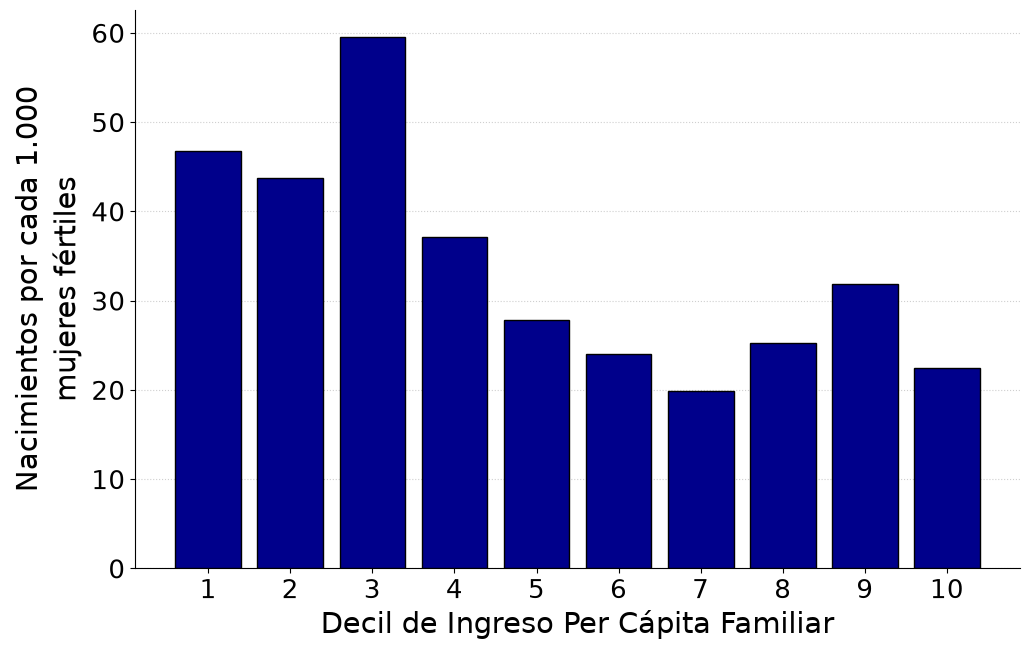

In [10]:
def get_weighted_deciles(df, value_col, weight_col):
    valid = df[value_col].notna() & df[weight_col].notna() & (df[weight_col] > 0)
    df_valid = df[valid].sort_values(value_col)
    cum = df_valid[weight_col].cumsum()
    deciles = pd.cut(cum / cum.iloc[-1], bins=np.linspace(0, 1, 11), labels=range(1, 11), include_lowest=True)
    return deciles.astype('Int64').reindex(df.index)


def imputar_status_mediana(df):
    st = df['status'].astype(float)
    st = st.fillna(df.groupby(['education', 'sex', 'clima_educativo', 'provincia'])['status'].transform('median'))
    st = st.fillna(df.groupby(['education', 'sex'])['status'].transform('median'))
    return st.fillna(st.median()).round().astype(int)


def asignar_nietos_a_hijas(df, edad_col):
    idx = df.index
    vacio_n, vacio_age, vacio_m = pd.Series(0.0, index=idx), pd.Series(99.0, index=idx), pd.Series(0, index=idx)
    nietos = (df.loc[df["ch03"] == 5, ["hogar_id", edad_col]].rename(columns={edad_col: "edad_nieto"})
              .reset_index().rename(columns={"index": "idx_nieto"}))
    hijas = (df.loc[(df["ch03"] == 3) & (df["sex"] == 1) & (df[edad_col].between(15, 50)), ["hogar_id", edad_col]]
             .rename(columns={edad_col: "edad_hija"}).reset_index().rename(columns={"index": "idx_hija"}))
    if nietos.empty or hijas.empty:
        return vacio_n, vacio_age, vacio_m
    pares = nietos.merge(hijas, on="hogar_id", how="inner")
    pares = pares[pares["edad_hija"] >= pares["edad_nieto"] + 15]
    if pares.empty:
        return vacio_n, vacio_age, vacio_m
    pares = pares.sort_values(["idx_nieto", "edad_hija", "idx_hija"], ascending=[True, False, True])
    adj = pares.drop_duplicates(subset="idx_nieto", keep="first")
    min_age = pd.Series(idx.map(adj.groupby("idx_hija")["edad_nieto"].min()), index=idx).astype(float).fillna(99.0)
    return (pd.Series(idx.map(adj.groupby("idx_hija").size()), index=idx).astype(float).fillna(0.0),
            min_age, (min_age == 0).astype(int))


year = 2024
df = pd.read_csv(f'datos/eph/personas_tot.urb_3T_{year}.txt', sep=';', decimal=',', low_memory=False)
df.columns = df.columns.str.lower()
for col in ["ch12", "ch13", "ch14", "ipcf", "pondih", "pondera"]:
    if df[col].dtype == object:
        df[col] = df[col].astype(str).str.replace(',', '.', regex=False)
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
df["age"] = pd.to_numeric(df["ch06"], errors='coerce').fillna(99).astype(int)
df["age"] = np.where(df["age"] == -1, 0, df["age"])
df["sex"] = df["ch04"].map({2: 1, 1: 0})
df["education"] = pd.to_numeric(df["nivel_ed"], errors='coerce').fillna(0).astype(int).replace(7, 0)
df["provincia"] = df["aglomerado"]
df["hogar_id"] = df["codusu"].astype(str) + "_" + df["nro_hogar"].astype(str) + f"_{year}"
df["ed_years"] = get_ed_years(df)
df = df.merge(df[df["age"] >= 18].groupby("hogar_id")["ed_years"].mean().rename("average_years"),
              on="hogar_id", how="left")
df["clima_educativo"] = (pd.cut(df["average_years"], bins=[-np.inf, 7, 11, 14, 16, np.inf], labels=[0, 1, 2, 3, 4],
                                right=False).astype("float").fillna(0).astype(int))
df["status"] = get_weighted_deciles(df, "ipcf", "pondih")
df["status"] = imputar_status_mediana(df)

hijos_jefe = (df[df["ch03"] == 3].groupby("hogar_id")
              .agg(children_jefe=("age", "count"), min_child_age_jefe=("age", "min")).reset_index())
nietos_jefe = (df[df["ch03"] == 5].groupby("hogar_id")
               .agg(nietos_hh=("age", "count"), min_nieto_age=("age", "min")).reset_index())
df = df.merge(hijos_jefe, on="hogar_id", how="left").merge(nietos_jefe, on="hogar_id", how="left")
df["children_jefe"] = df["children_jefe"].fillna(0)
nietos_asig, min_nieto_asig, _ = asignar_nietos_a_hijas(df, edad_col="age")

mujeres = df[(df["sex"] == 1) & (df["age"].between(15, 50))].copy()
cond_jefa, cond_hija = mujeres["ch03"].isin([1, 2]), mujeres["ch03"] == 3
mujeres["youngest_age"] = np.where(cond_jefa, mujeres["min_child_age_jefe"],
                                   np.where(cond_hija, min_nieto_asig.loc[mujeres.index], 99)).astype(float)
mujeres["target_motherhood"] = (mujeres["youngest_age"].fillna(99) == 0).astype(int)

factor_edad0 = float(pd.read_csv(DIR_IN / "factores_correccion_edad0.csv").set_index("year")["factor_f"].loc[year])
mujeres['nacimientos_w'] = mujeres['target_motherhood'] * mujeres['pondera'] * factor_edad0
resultados = mujeres.groupby('status').agg(mujeres_fertiles=('pondera', 'sum'),
                                          nacimientos=('nacimientos_w', 'sum')).reset_index()
resultados['tasa_fecundidad_x1000'] = np.where(resultados['mujeres_fertiles'] > 0,
                                               resultados['nacimientos'] / resultados['mujeres_fertiles'] * 1000, 0)
resultados[['status', 'tasa_fecundidad_x1000']].to_csv(DIR_TAB / "tasa_fecundidad_status_2024.csv", index=False)

FS_TICK, FS_LABEL = 19, 21
fig, ax = plt.subplots(figsize=(10.4, 6.6))
ax.bar(resultados['status'], resultados['tasa_fecundidad_x1000'], color="darkblue", edgecolor="black", zorder=3)
ax.set_xlabel("Decil de Ingreso Per Cápita Familiar", fontsize=FS_LABEL)
ax.set_ylabel("Nacimientos por cada 1.000\nmujeres fértiles", fontsize=FS_LABEL, linespacing=1.3)
ax.set_xticks(range(1, 11))
ax.tick_params(axis="both", labelsize=FS_TICK)
ax.grid(axis="y", linestyle=":", alpha=0.6, zorder=0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(DIR_FIG / "barras_tradeoff_natalidad_2024.png", dpi=300, bbox_inches="tight")
plt.show()

## Apéndice · Comparación con las estadísticas vitales y clima educativo en cinco categorías

In [11]:
def _norm(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()


NOMBRE_JURISDICCION = {2: "ciud. aut. de buenos aires", 6: "buenos aires", 10: "catamarca", 14: "cordoba",
                       18: "corrientes", 22: "chaco", 26: "chubut", 30: "entre rios", 34: "formosa", 38: "jujuy",
                       42: "la pampa", 46: "la rioja", 50: "mendoza", 54: "misiones", 58: "neuquen",
                       62: "rio negro", 66: "salta", 70: "san juan", 74: "san luis", 78: "santa cruz",
                       82: "santa fe", 86: "santiago del estero", 90: "tucuman", 94: "tierra del fuego"}
JURISDICCIONES_URBANAS = {2, 6, 26, 78, 94}


def _eph_basica(anio):
    d = pd.read_parquet(DIR_IN / f"personas_tot.urb_3T_{anio}_pondera_corregida.parquet",
                        columns=["codusu", "nro_hogar", "provincia", "edad_eph", "pondera", "pondera_orig"])
    d["provincia"] = pd.to_numeric(d["provincia"])
    d["b_orig"] = np.where(d["edad_eph"] == 0, d["pondera_orig"], 0.0)
    d["b_ajust"] = np.where(d["edad_eph"] == 0, d["pondera"], 0.0)
    d["hogar"] = d["codusu"].astype(str) + "|" + d["nro_hogar"].astype(str) + f"|{anio}"
    return d


tbn_vitales = pd.read_csv("datos/deis/natalidad_nacional.csv").set_index("year")["natality"]
filas = []
for anio in range(2016, 2023):
    d = _eph_basica(anio)
    pob = d["pondera_orig"].sum()
    filas.append(dict(year=anio, tbn_eph_original=d["b_orig"].sum() / pob * 1000,
                      tbn_estadisticas_vitales=tbn_vitales.loc[anio],
                      cociente_original=d["b_orig"].sum() / pob * 1000 / tbn_vitales.loc[anio],
                      cociente_ajustado=d["b_ajust"].sum() / pob * 1000 / tbn_vitales.loc[anio]))
validacion_nacional = pd.DataFrame(filas)
validacion_nacional.to_csv(DIR_TAB / "validacion_nacional.csv", index=False)
print(f"promedio de los cocientes: original {validacion_nacional['cociente_original'].mean():.2f}, "
      f"ajustado {validacion_nacional['cociente_ajustado'].mean():.2f}")
validacion_nacional.round(2)

promedio de los cocientes: original 0.81, ajustado 0.89


,year,tbn_eph_original,tbn_estadisticas_vitales,cociente_original,cociente_ajustado
0,2016,13.56,16.79,0.81,0.88
1,2017,11.88,16.16,0.74,0.80
2,2018,12.30,15.33,0.80,0.88
3,2019,11.57,13.90,0.83,0.91
4,2020,9.81,11.80,0.83,0.91
5,2021,8.90,11.68,0.76,0.83
6,2022,10.17,10.93,0.93,1.02


In [12]:
filas, micro = [], []
for anio in (2022, 2023, 2024):
    reg = pd.read_csv(f"datos/deis/natalidad_{anio}.txt", dtype=str)
    reg["j"] = reg["Jurisdiccion"].map(_norm)
    d = _eph_basica(anio)
    for prov, nombre in NOMBRE_JURISDICCION.items():
        r = reg[reg["j"] == nombre].iloc[0]
        dd = d[d["provincia"] == prov]
        filas.append(dict(year=anio, provincia=prov, pob_registro=float(r["Poblacion"].replace(".", "")),
                          nac_registro=float(r["Nacimientos"].replace(".", "")), pob_eph=dd["pondera_orig"].sum(),
                          nac_eph_orig=dd["b_orig"].sum(), nac_eph_ajust=dd["b_ajust"].sum(),
                          casos_edad0=int((dd["edad_eph"] == 0).sum())))
    micro.append(d[d["provincia"].isin(JURISDICCIONES_URBANAS)])
jur = pd.DataFrame(filas)
jur["grupo"] = np.where(jur["provincia"].isin(JURISDICCIONES_URBANAS), "Jurisdicciones urbanas", "Resto del país")


def _resumen(g):
    tbn_reg = g["nac_registro"].sum() / g["pob_registro"].sum()
    return pd.Series({"cobertura_eph": g["pob_eph"].sum() / g["pob_registro"].sum(),
                      "casos_edad0": g["casos_edad0"].sum(),
                      "cociente_original": g["nac_eph_orig"].sum() / g["pob_eph"].sum() / tbn_reg,
                      "cociente_ajustado": g["nac_eph_ajust"].sum() / g["pob_eph"].sum() / tbn_reg})


validacion_jur = pd.concat([jur.groupby("grupo").apply(_resumen),
                            _resumen(jur).to_frame("Total").T]).reset_index(names="grupo")

urb = pd.concat(micro, ignore_index=True)
tbn_reg_urb = (jur.loc[jur["grupo"] == "Jurisdicciones urbanas", "nac_registro"].sum()
               / jur.loc[jur["grupo"] == "Jurisdicciones urbanas", "pob_registro"].sum())
codes, uniq = pd.factorize(urb["hogar"])
pob_u, b0_u, b1_u = urb["pondera_orig"].to_numpy(), urb["b_orig"].to_numpy(), urb["b_ajust"].to_numpy()
rng_val = np.random.default_rng(0)
boot_o, boot_a = [], []
for _ in range(1000):
    mult = rng_val.multinomial(len(uniq), np.full(len(uniq), 1 / len(uniq)))[codes]
    P = (mult * pob_u).sum()
    boot_o.append((mult * b0_u).sum() / P / tbn_reg_urb)
    boot_a.append((mult * b1_u).sum() / P / tbn_reg_urb)
validacion_jur["IC95_original"] = ""
validacion_jur["IC95_ajustado"] = ""
_i = validacion_jur["grupo"] == "Jurisdicciones urbanas"
validacion_jur.loc[_i, "IC95_original"] = "[{:.2f} ; {:.2f}]".format(*np.percentile(boot_o, [2.5, 97.5]))
validacion_jur.loc[_i, "IC95_ajustado"] = "[{:.2f} ; {:.2f}]".format(*np.percentile(boot_a, [2.5, 97.5]))
validacion_jur.to_csv(DIR_TAB / "validacion_jurisdicciones.csv", index=False)

por_jur = jur.groupby("provincia").apply(_resumen)
print(f"correlación entre cobertura y cociente (24 jurisdicciones): "
      f"{np.corrcoef(por_jur['cobertura_eph'], por_jur['cociente_original'])[0, 1]:.2f}")
print("cociente anual de las jurisdicciones urbanas:")
print(jur[jur["grupo"] == "Jurisdicciones urbanas"].groupby("year").apply(_resumen)[
    ["cociente_original", "cociente_ajustado"]].round(2))
validacion_jur

correlación entre cobertura y cociente (24 jurisdicciones): 0.55
cociente anual de las jurisdicciones urbanas:
      cociente_original  cociente_ajustado
year                                      
2022               1.12               1.22
2023               0.82               0.90
2024               1.06               1.16


,grupo,cobertura_eph,casos_edad0,cociente_original,cociente_ajustado,IC95_original,IC95_ajustado
0,Jurisdicciones urbanas,0.980420,382.0,1.002667,1.096271,[0.87 ; 1.16],[0.95 ; 1.27]
1,Resto del país,0.860851,1410.0,0.868891,0.950006,,
2,Total,0.917681,1792.0,0.924663,1.010985,,


In [13]:
CLIMA5 = ["Muy bajo (menos de 7 años)", "Bajo (7 a menos de 11)", "Medio (11 a menos de 14)",
          "Alto (14 a menos de 16)", "Muy alto (16 o más)"]
filas = []
for anio in (Y0, Y1):
    m = muj[muj["year"] == anio]
    c5 = pd.cut(m["clima_anios"], [-np.inf, 7, 11, 14, 16, np.inf], right=False, labels=CLIMA5)
    s = m.groupby(c5, observed=True)["pondera"].sum()
    filas.append((s / s.sum() * 100).rename(anio))
clima_cinco = pd.concat(filas, axis=1).reindex(CLIMA5).reset_index(names="clima_educativo_hogar")
clima_cinco.to_csv(DIR_TAB / "clima_educativo_cinco_categorias.csv", index=False)
clima_cinco.round(1)

,clima_educativo_hogar,2016,2024
0,Muy bajo (menos de 7 años),14.2,7.0
1,Bajo (7 a menos de 11),39.9,34.7
2,Medio (11 a menos de 14),30.2,37.7
3,Alto (14 a menos de 16),11.8,14.8
4,Muy alto (16 o más),3.9,5.7
